# Stock Analysis project
Done by Souvik Ahmed
ID: 203014004


1. Setup and Data Retrieval

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

import yfinance as yf

In [81]:
stock_symbol = 'AAPL'
start_date = '2018-01-01'
end_date = '2022-12-31'

stock_data = yf.download(stock_symbol, start=start_date, end=end_date)

[*********************100%***********************]  1 of 1 completed


In [82]:
print("The first 5 rows of stock data are as follows: ")
print(stock_data.head())

The first 5 rows of stock data are as follows: 
Price       Adj Close      Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                                        
2018-01-02  40.524345  43.064999  43.075001  42.314999  42.540001  102223600
2018-01-03  40.517288  43.057499  43.637501  42.990002  43.132500  118071600
2018-01-04  40.705494  43.257500  43.367500  43.020000  43.134998   89738400
2018-01-05  41.168926  43.750000  43.842499  43.262501  43.360001   94640000
2018-01-08  41.016022  43.587502  43.902500  43.482498  43.587502   82271200


2. Data Exploration

In [83]:
highest_price = stock_data['High'].max()
lowest_price = stock_data['Low'].min()
print(f"\nHighest stock price: {highest_price}")
print(f"Lowest stock price: {lowest_price}")


Highest stock price: Ticker
AAPL    182.940002
dtype: float64
Lowest stock price: Ticker
AAPL    35.5
dtype: float64


In [84]:
#printing average closing price for each year
stock_data['Year'] = stock_data.index.year
average_closing_price = stock_data.groupby('Year')['Close'].mean()
print("\nAverage closing price for each year is as follows:")
print(average_closing_price)


Average closing price for each year is as follows:
Price        Close
Ticker        AAPL
Year              
2018     47.263357
2019     52.063988
2020     95.347075
2021    140.989365
2022    154.835060


In [85]:
#monthly average volumes of shares traded
stock_data['Month'] = stock_data.index.to_period('M')
monthly_average_volume = stock_data.groupby('Month')['Volume'].mean()
print("\nMonthly average volumes of shares traded are as follows:")
print(monthly_average_volume)


Monthly average volumes of shares traded are as follows:
Price          Volume
Ticker           AAPL
Month                
2018-01  1.256532e+08
2018-02  1.953462e+08
2018-03  1.359481e+08
2018-04  1.268865e+08
2018-05  1.129048e+08
2018-06  1.004999e+08
2018-07  7.498884e+07
2018-08  1.217946e+08
2018-09  1.429415e+08
2018-10  1.373476e+08
2018-11  1.831098e+08
2018-12  1.892468e+08
2019-01  1.577309e+08
2019-02  9.948223e+07
2019-03  1.239965e+08
2019-04  9.640337e+07
2019-05  1.344467e+08
2019-06  1.030437e+08
2019-07  8.615485e+07
2019-08  1.238330e+08
2019-09  1.085134e+08
2019-10  1.057918e+08
2019-11  8.966630e+07
2019-12  1.137521e+08
2020-01  1.397319e+08
2020-02  1.589094e+08
2020-03  2.854578e+08
2020-04  1.554904e+08
2020-05  1.402968e+08
2020-06  1.474262e+08
2020-07  1.372856e+08
2020-08  1.938124e+08
2020-09  1.850117e+08
2020-10  1.315758e+08
2020-11  1.061539e+08
2020-12  1.055541e+08
2021-01  1.179085e+08
2021-02  9.651872e+07
2021-03  1.152356e+08
2021-04  8.999321e

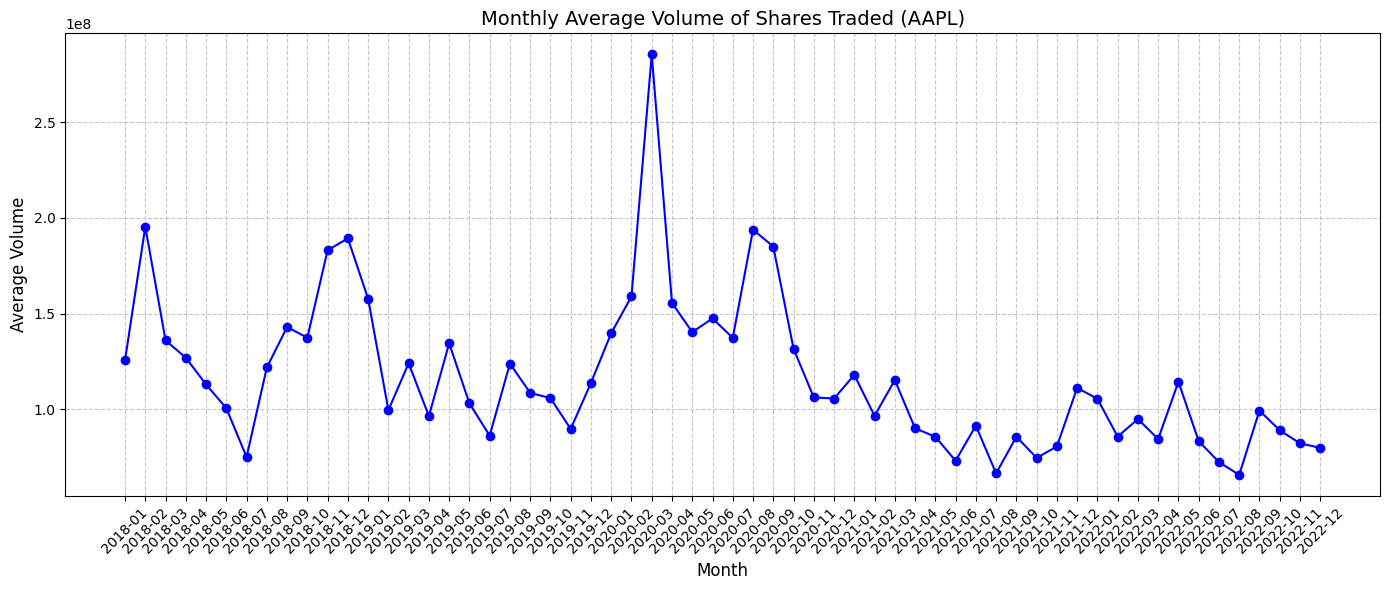

In [86]:
# Monthly average trading volume for AAPL
monthly_avg_volume = stock_data.groupby('Month')['Volume'].mean()

# Plotting the monthly average volumes
plt.figure(figsize=(14, 6))
plt.plot(monthly_avg_volume.index.astype(str), monthly_avg_volume, marker='o', linestyle='-', color='blue')
plt.title('Monthly Average Volume of Shares Traded (AAPL)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Volume', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [87]:
#check for missing data and handle it by filling with mean
missing_data_count = stock_data.isnull().sum()
print("\nNumber of missing data points in each column:")
print(missing_data_count)


Number of missing data points in each column:
Price      Ticker
Adj Close  AAPL      0
Close      AAPL      0
High       AAPL      0
Low        AAPL      0
Open       AAPL      0
Volume     AAPL      0
Year                 0
Month                0
dtype: int64


In [88]:
#fill missing values with column mean
#there is no need to fill missing values since there are none, but we do it anyways
stock_data.fillna(stock_data.median(), inplace=True)
missing_data_count_after = stock_data.isnull().sum()
print("\nNumber of missing data points in each column after filling:")
print(missing_data_count_after)


Number of missing data points in each column after filling:
Price      Ticker
Adj Close  AAPL      0
Close      AAPL      0
High       AAPL      0
Low        AAPL      0
Open       AAPL      0
Volume     AAPL      0
Year                 0
Month                0
dtype: int64


3. Time Series Analysis

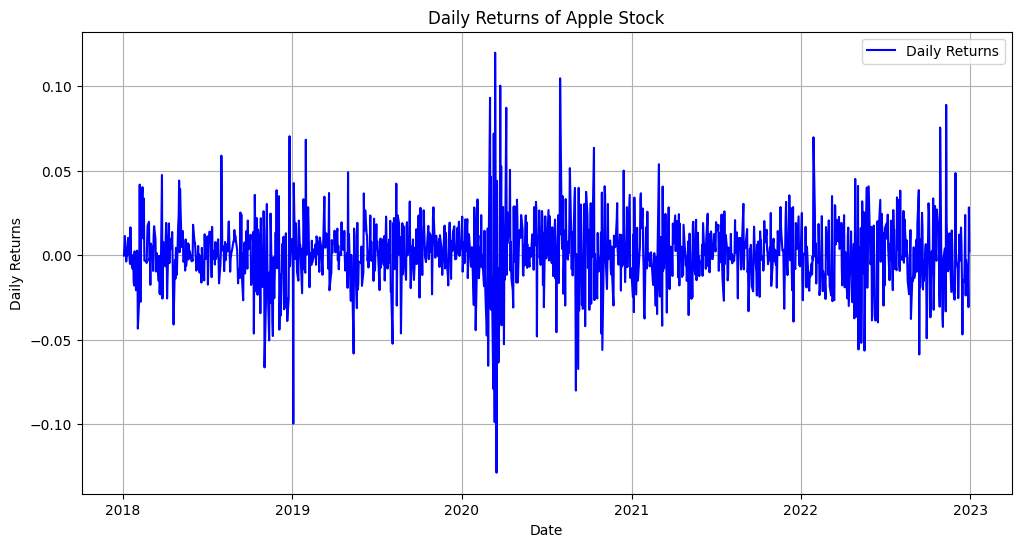

In [89]:
# calculate the daily returns using the adjusted close price
stock_data['Daily Returns'] = stock_data['Adj Close'].pct_change()

#plot the daily returns over time
plt.figure(figsize=(12, 6))
plt.plot(stock_data['Daily Returns'], color='blue', label='Daily Returns')
plt.title('Daily Returns of Apple Stock')
plt.xlabel('Date')
plt.ylabel('Daily Returns')
plt.legend()
plt.grid(True)
plt.show()

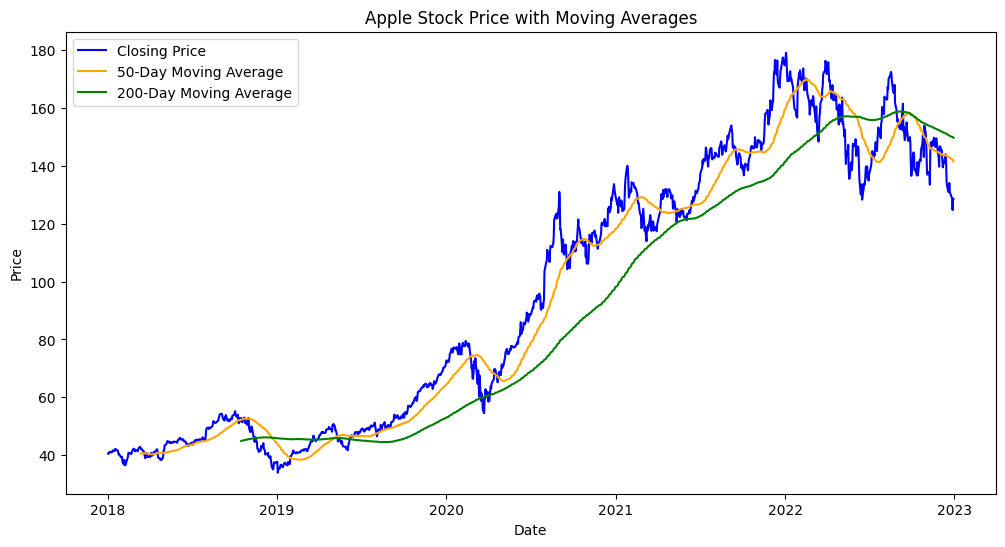

In [90]:
#plot the moving averages for 50-day and 200-day windows
stock_data['50-Day MA'] = stock_data['Adj Close'].rolling(window=50).mean()
stock_data['200-Day MA'] = stock_data['Adj Close'].rolling(window=200).mean()

plt.figure(figsize=(12, 6))
plt.plot(stock_data['Adj Close'], label='Closing Price', color='blue')
plt.plot(stock_data['50-Day MA'], label='50-Day Moving Average', color='orange')
plt.plot(stock_data['200-Day MA'], label='200-Day Moving Average', color='green')
plt.title('Apple Stock Price with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

4. Correlation Analysis

In [91]:
#pick another stock and download its historical data
#we are using S&P 500 Index

sp500_symbol = '^GSPC'
sp500_data = yf.download(sp500_symbol, start=start_date, end=end_date)

[*********************100%***********************]  1 of 1 completed


In [92]:
highest_price = sp500_data['High'].max()
lowest_price = sp500_data['Low'].min()
print(f"\nHighest stock price: {highest_price}")
print(f"Lowest stock price: {lowest_price}")


Highest stock price: Ticker
^GSPC    4818.620117
dtype: float64
Lowest stock price: Ticker
^GSPC    2191.860107
dtype: float64


In [93]:
#calculate daily returns for the S&P 500 Index
sp500_data['Daily Returns'] = sp500_data['Adj Close'].pct_change()

In [94]:
#calculate the correlation between daily returns of AAPL and S&P500 index
correlation = stock_data['Daily Returns'].corr(sp500_data['Daily Returns'])
print(f"\nCorrelation between daily returns of AAPL and S&P500 index: {correlation}")



Correlation between daily returns of AAPL and S&P500 index: 0.8019690342503137


In [95]:
#interpret correlation result

if correlation > 0.6:
    print("There is a strong positive correlation between daily returns of AAPL and S&P500 index.")
elif 0.3 <= correlation <= 0.6:
    print("There is a moderate positive correlation between daily returns of AAPL and S&P500 index.")
elif -0.3 <= correlation < 0.3:
    print("There is a weak positive correlation between daily returns of AAPL and S&P500 index.")
else:
    print("There is a negative correlation between daily returns of AAPL and S&P500 index.")


There is a strong positive correlation between daily returns of AAPL and S&P500 index.


5. Visualization

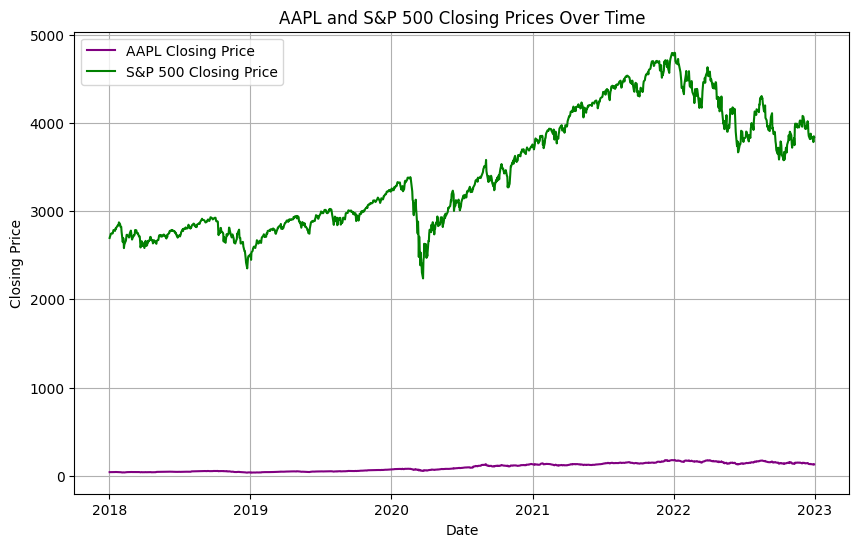

In [96]:
#line plot of closing price for both stocks over time
plt.figure(figsize=(10, 6))
plt.plot(stock_data['Adj Close'], label='AAPL Closing Price', color='Purple')
plt.plot(sp500_data['Adj Close'], label='S&P 500 Closing Price', color='Green')
plt.title('AAPL and S&P 500 Closing Prices Over Time')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.show()

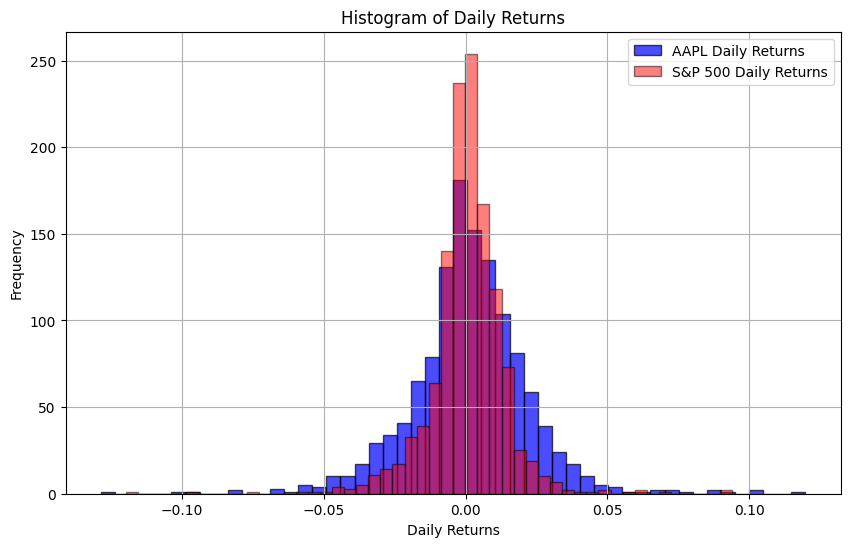

In [97]:
#Histogram of daily returns to show the frequency of returns
plt.figure(figsize=(10, 6))
plt.hist(stock_data['Daily Returns'].dropna(), bins=50, color='blue', edgecolor='black', label='AAPL Daily Returns', alpha=0.7)
plt.hist(sp500_data['Daily Returns'].dropna(), bins=50, color='red', edgecolor='black', alpha=0.5, label='S&P 500 Daily Returns')
plt.title('Histogram of Daily Returns')
plt.xlabel('Daily Returns')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()


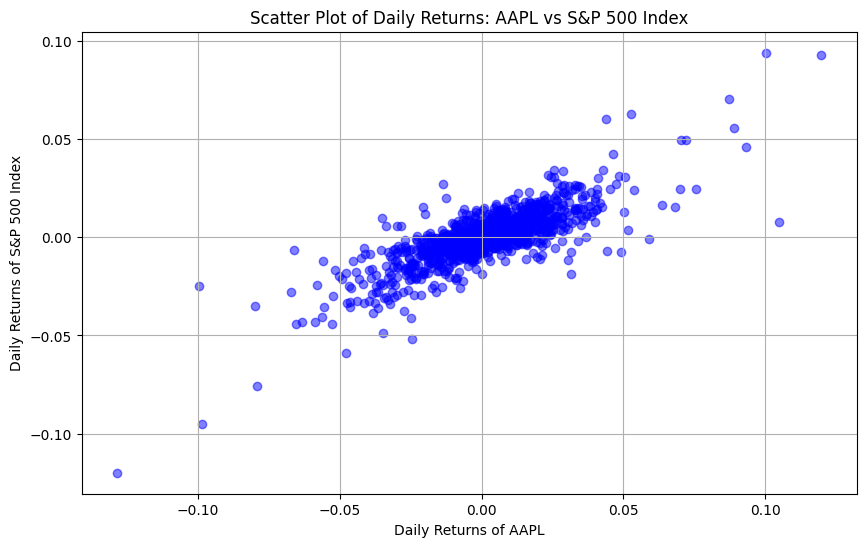

In [98]:
# Scatter plot for the correlation analysis
plt.figure(figsize=(10, 6))
plt.scatter(stock_data['Daily Returns'], sp500_data['Daily Returns'], alpha=0.5, color='blue')
plt.title('Scatter Plot of Daily Returns: AAPL vs S&P 500 Index')
plt.xlabel('Daily Returns of AAPL')
plt.ylabel('Daily Returns of S&P 500 Index')
plt.grid(True)
plt.show()

6. Saving work

In [99]:
#Save final DataFrame with the calculated metrics to a CSV file
stock_data.to_csv('stock_analysis.csv', index=True)
print("Saved the dataframe as stock_analysis.csv")

Saved the dataframe as stock_analysis.csv
